# 09 · The matching ladder, scored against the final set

Does more sophisticated matching earn its complexity? Every rung is scored on the 600
in-domain pairs against the one final Fit / No Fit set (D41, D47), for `generic`,
`targeted` and the total, with CIs resampling JDs. The decision rule and the comparisons
were registered before the held-out rungs ran
(`plan/2026-09-26-top-down-reset/06-registration.md`).

Read from `output/matching/indomain-metrics.json`. Rebuild with
`uv run python -m candidate_screener.evaluation.indomain --seed 0`.

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd

from candidate_screener import reporting
from candidate_screener.evaluation import indomain

reporting.style(plt)
record = json.loads(indomain.RECORD.read_text(encoding="utf-8"))
costs = json.loads(indomain.COSTS.read_text(encoding="utf-8"))
print(f"reference: {record['reference']['file']} rule v{record['reference']['rule_version']}")

reference: a2-final-labels.csv rule v1


## Per-JD AUC, every rung (all pairs)

Is a Fit candidate ranked above a No Fit one for the same job? 0.5 is chance.

In [2]:
rows = []
for name, block in record["systems"].items():
    f = {(x["metric"], x["scope"]): x for x in block["figures"] if x["subset"] == "all"}
    rows.append({"system": name, "rung": block["rung"], "status": block["status"],
                 **{s: round(f[("auc", s)]["value"], 3) for s in ("generic", "targeted", "total")},
                 "total CI": f"[{f[('auc', 'total')]['ci_low']:.2f}, {f[('auc', 'total')]['ci_high']:.2f}]",
                 "within-family (total)": round(f[("within_family_auc", "total")]["value"], 3)
                 if ("within_family_auc", "total") in f else None,
                 "ms / 500-candidate role": costs[name]["ms_per_500_candidate_role"]})
table = pd.DataFrame(rows)
table

,system,rung,status,generic,targeted,total,total CI,within-family (total),ms / 500-candidate role
0,random,0,exploratory,0.558,0.552,0.556,"[0.50, 0.61]",0.580,0.9
1,keyword match,1a,exploratory,0.786,0.726,0.766,"[0.72, 0.80]",0.500,0.8
2,metadata rules,1a,exploratory,0.776,0.784,0.778,"[0.73, 0.82]",0.540,1.5
3,skill overlap,1b,held-out,0.719,0.676,0.705,"[0.65, 0.76]",0.648,157.5
4,metadata + skill overlap,1a+1b,held-out,0.818,0.830,0.822,"[0.78, 0.86]",0.644,172.8
5,TF-IDF,2,exploratory,0.792,0.808,0.797,"[0.75, 0.84]",0.724,526.4
6,BM25,2,exploratory,0.613,0.681,0.636,"[0.58, 0.69]",0.625,81.8
7,metadata + TF-IDF,1a+2,exploratory,0.848,0.849,0.849,"[0.80, 0.89]",0.708,583.1
8,metadata + BM25,1a+2,exploratory,0.811,0.833,0.819,"[0.77, 0.86]",0.629,79.3
9,SBERT (zero-shot),3a,exploratory,0.789,0.746,0.774,"[0.73, 0.82]",0.755,8.8


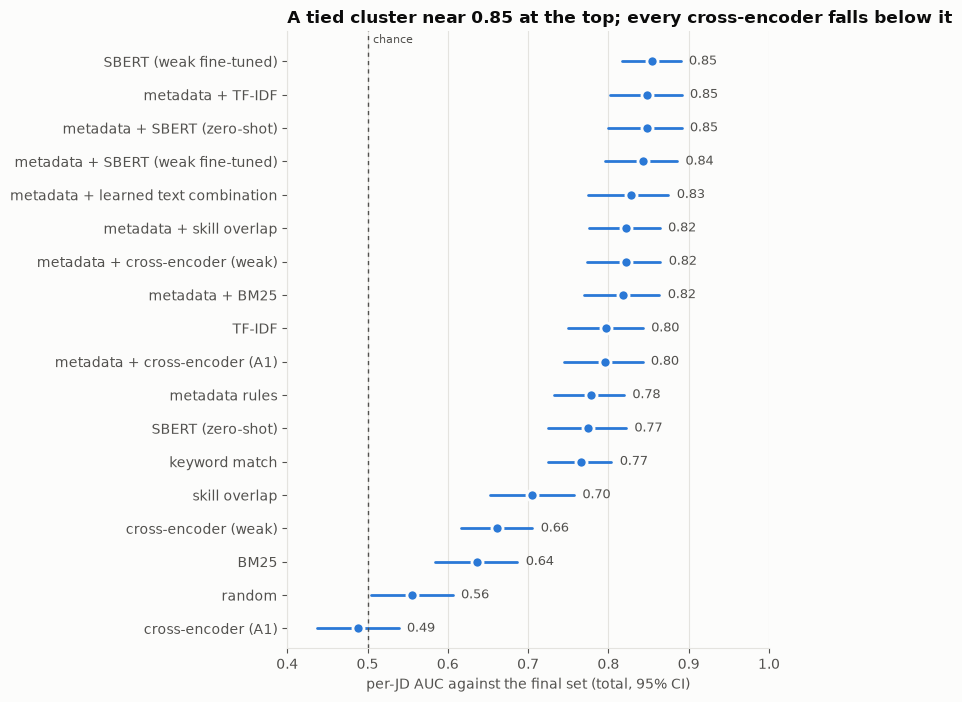

In [3]:
order = table.sort_values("total")
fig, ax = plt.subplots(figsize=(8, 0.34 * len(order) + 1))
figs = {n: {(x["metric"], x["scope"]): x for x in b["figures"] if x["subset"] == "all"}
        for n, b in record["systems"].items()}
reporting.dot_ci(ax, list(order.system)[::-1],
                 [figs[n][("auc", "total")]["value"] for n in order.system][::-1],
                 [figs[n][("auc", "total")]["ci_low"] for n in order.system][::-1],
                 [figs[n][("auc", "total")]["ci_high"] for n in order.system][::-1],
                 ref=0.5, ref_label="chance")
ax.set_xlabel("per-JD AUC against the final set (total, 95% CI)")
ax.set_title("A tied cluster near 0.85 at the top; every cross-encoder falls below it")
ax.set_xlim(0.4, 1.0)
plt.tight_layout()

## The registered comparisons (decision rule, registration §2)

Paired per-JD deltas B − A on the total, with the strata as a consistency check and the `llm_free` subset as the LLM-dependence check.

In [4]:
from candidate_screener.matching import selection

rows = []
for cid in dict.fromkeys(x["id"] for x in record["deltas"]):
    d = {(x["scope"], x["subset"]): x for x in record["deltas"] if x["id"] == cid and x["metric"] == "auc"}
    t = d[("total", "all")]
    rows.append({"id": cid, "B": t["b"], "A": t["a"], "Δ total": t["delta"], "CI": t["ci"],
                 "Δ generic": d[("generic", "all")]["delta"], "Δ targeted": d[("targeted", "all")]["delta"],
                 "Δ llm_free": d[("total", "llm_free")]["delta"], "verdict": selection.verdict_of(d)})
pd.DataFrame(rows)

,id,B,A,Δ total,CI,Δ generic,Δ targeted,Δ llm_free,verdict
0,C1,skill overlap,random,0.148720,"[0.078707, 0.21826]",0.161517,0.123768,0.157644,justified
1,C2,metadata + skill overlap,metadata rules,0.043536,"[0.024287, 0.064991]",0.042065,0.046405,0.046385,justified
2,C3,SBERT (zero-shot),TF-IDF,-0.023156,"[-0.080677, 0.036544]",-0.003447,-0.061589,-0.019953,not resolved
3,C4,metadata + SBERT (zero-shot),metadata + TF-IDF,-0.000884,"[-0.024196, 0.021693]",0.000442,-0.003470,0.008467,not resolved
4,C5,SBERT (weak fine-tuned),TF-IDF,0.056907,"[0.009416, 0.105887]",0.079731,0.012399,0.031649,justified
5,C6,metadata + SBERT (weak fine-tuned),metadata + TF-IDF,-0.005694,"[-0.02974, 0.01714]",-0.003043,-0.010863,-0.013640,not resolved
6,C7,cross-encoder (A1),TF-IDF,-0.309202,"[-0.370203, -0.244934]",-0.260518,-0.404137,-0.340754,harmful
7,C8,metadata + cross-encoder (A1),metadata + TF-IDF,-0.052432,"[-0.08333, -0.021856]",-0.048408,-0.060280,-0.040797,harmful
8,C9,cross-encoder (weak),TF-IDF,-0.136396,"[-0.201323, -0.0707]",-0.124914,-0.158786,-0.201364,harmful
9,C10,metadata + cross-encoder (weak),metadata + TF-IDF,-0.027131,"[-0.059596, 0.00713]",-0.030541,-0.020482,-0.037125,not resolved


## Selection (registration §4): the cheapest rung no justified, more expensive rung beats

Every more expensive rung in the context is checked, not only the listed comparisons.

In [5]:
for context, s in record["selection"].items():
    print(f"[{context}] selected: {s['selected']}")
    for step in s["trail"]:
        print(f"   cost {step['cost']} {step['rung']:38} AUC {step['auc_total']:.3f}  beaten by: {step['beaten_by'] or '—'}")

[metadata] selected: metadata + TF-IDF
   cost 1 random                                 AUC 0.556  beaten by: ['keyword match', 'metadata rules', 'metadata + skill overlap', 'skill overlap', 'TF-IDF', 'metadata + TF-IDF', 'BM25', 'metadata + BM25', 'SBERT (zero-shot)', 'metadata + SBERT (zero-shot)', 'SBERT (weak fine-tuned)', 'metadata + SBERT (weak fine-tuned)', 'cross-encoder (weak)', 'metadata + cross-encoder (A1)', 'metadata + cross-encoder (weak)', 'metadata + learned text combination']
   cost 2 metadata rules                         AUC 0.778  beaten by: ['metadata + skill overlap', 'metadata + TF-IDF', 'metadata + BM25', 'metadata + SBERT (zero-shot)', 'SBERT (weak fine-tuned)', 'metadata + SBERT (weak fine-tuned)', 'metadata + cross-encoder (weak)', 'metadata + learned text combination']
   cost 2 keyword match                          AUC 0.766  beaten by: ['metadata + skill overlap', 'metadata + TF-IDF', 'metadata + BM25', 'metadata + SBERT (zero-shot)', 'SBERT (weak fine-t

## Rungs that emit Fit / No Fit

Against the always-Fit floor. The provisional S1 bar is accuracy ≥ 0.85 and binary macro-F1 ≥ 0.85 (registration §5).

In [6]:
print("always-Fit accuracy floor:", record["classifier_floor_always_fit_accuracy"])
rows = []
for name, block in record["classifiers"].items():
    f = {(x["metric"], x["scope"]): x for x in block["figures"] if x["subset"] == "all"}
    rows.append({"classifier": name[:60], **{m: round(f[(m, "total")]["value"], 3)
                                            for m in ("accuracy", "macro_f1", "f1_fit", "kappa")}})
pd.DataFrame(rows)

always-Fit accuracy floor: {'generic': 0.625, 'targeted': 0.585, 'total': 0.611667}


,classifier,accuracy,macro_f1,f1_fit,kappa
0,"cross-encoder (A1) (threshold 0.6361, from its...",0.537,0.533,0.576,0.081
1,"cross-encoder (weak) (threshold 0.5300, from i...",0.575,0.575,0.574,0.191
2,metadata rule (Fit iff keyword match),0.768,0.721,0.836,0.465


**Reading.** See `plan/2026-09-26-top-down-reset/07-selection.md` for the verdicts and
the selected pipeline (D48). Every figure is agreement with the documented panel rule of
notebook 08, not correctness. Richer rungs are compared with the fixed cheap champion,
`metadata + TF-IDF`, named before any held-out result existed.